
# Checkout Redesign A/B Test & Multi-Touch Marketing Attribution

**Business questions:**
1. Did the new checkout flow actually improve conversion — and is the result
   statistically reliable, not just noise? Did it hurt anything else (page
   load time, order value)?
2. Which marketing channels deserve credit for conversions, and does the
   answer change budget decisions depending on which attribution model you
   trust?

**Tools:** Python (`scipy`/`statsmodels`) for hypothesis testing and power
analysis, SQL for attribution-model credit assignment via window functions,
Plotly/matplotlib for stakeholder-ready visuals.

**Datasets**
- `ab_test_sessions.csv` — 48,000 sessions from a 30-day randomized checkout
  A/B test (control vs. treatment), with device, traffic source, conversion,
  order value, and a guardrail metric (page load time).
- `touchpoints.csv` — 9,000 user marketing journeys (1-5 touchpoints across
  5 channels) with conversion outcome and value, for attribution modeling.
- `channel_spend.csv` — monthly spend/clicks per channel, for ROAS.


In [1]:

import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

conn = sqlite3.connect("../data/marketing.db")
def run_sql(path):
    with open(path) as f:
        return pd.read_sql_query(f.read(), conn)

ab = pd.read_sql_query("SELECT * FROM ab_sessions", conn)
print(f"{len(ab):,} sessions | {ab.session_date.min()} to {ab.session_date.max()} | "
      f"{ab.variant.value_counts().to_dict()}")


48,000 sessions | 2026-03-01 to 2026-03-30 | {'control': 24056, 'treatment': 23944}


## 1. Topline A/B Test Result

In [2]:

results = run_sql("../sql/01_ab_test_results.sql")
results


,device,variant,sessions,conversions,conversion_rate_pct,avg_order_value,avg_load_time_ms
0,ALL,control,24056,2164,9.00,73.94,1454.0
1,ALL,treatment,23944,2520,10.52,74.59,1490.0
2,Desktop,control,9031,1000,11.07,73.43,1455.0
3,Desktop,treatment,9098,974,10.71,74.78,1489.0
4,Mobile,control,15025,1164,7.75,74.37,1454.0
5,Mobile,treatment,14846,1546,10.41,74.48,1491.0


## 2. Is the topline lift statistically significant?

Two-proportion z-test on the blended (all-device) conversion rate, control vs. treatment.

In [3]:

ctrl = ab[ab.variant == "control"]
trt = ab[ab.variant == "treatment"]

count = np.array([trt.converted.sum(), ctrl.converted.sum()])
nobs = np.array([len(trt), len(ctrl)])
z_stat, p_value = proportions_ztest(count, nobs, alternative="larger")

ci_trt = proportion_confint(trt.converted.sum(), len(trt), alpha=0.05, method="wilson")
ci_ctrl = proportion_confint(ctrl.converted.sum(), len(ctrl), alpha=0.05, method="wilson")

print(f"Treatment conversion: {trt.converted.mean():.4f}  95% CI [{ci_trt[0]:.4f}, {ci_trt[1]:.4f}]")
print(f"Control conversion:   {ctrl.converted.mean():.4f}  95% CI [{ci_ctrl[0]:.4f}, {ci_ctrl[1]:.4f}]")
print(f"Absolute lift: {100*(trt.converted.mean()-ctrl.converted.mean()):.2f} pp")
print(f"z = {z_stat:.2f}, one-sided p-value = {p_value:.4f}")
print("=> Statistically significant at alpha=0.05" if p_value < 0.05 else "=> NOT significant at alpha=0.05")


Treatment conversion: 0.1052  95% CI [0.1014, 0.1092]
Control conversion:   0.0900  95% CI [0.0864, 0.0936]
Absolute lift: 1.53 pp
z = 5.64, one-sided p-value = 0.0000
=> Statistically significant at alpha=0.05


## 3. Was the test adequately powered?

Retrospective power check: given the observed effect size and sample size,
what statistical power did this test actually have? (You want to see this
*before* trusting a "no significant difference" result — an underpowered
test proves nothing.)

In [4]:

effect_size = proportion_effectsize(trt.converted.mean(), ctrl.converted.mean())
power_analysis = NormalIndPower()
achieved_power = power_analysis.power(effect_size=effect_size, nobs1=len(trt), alpha=0.05, ratio=len(ctrl)/len(trt))
print(f"Effect size (Cohen's h): {effect_size:.4f}")
print(f"Achieved statistical power: {achieved_power:.3f}")

required_n = power_analysis.solve_power(effect_size=effect_size, alpha=0.05, power=0.80, ratio=1.0)
print(f"Sample size per group required for 80% power at this effect size: {required_n:,.0f}")
print(f"Actual sample size per group: ~{len(trt):,}")


Effect size (Cohen's h): 0.0516
Achieved statistical power: 1.000
Sample size per group required for 80% power at this effect size: 5,906
Actual sample size per group: ~23,944


**Read:** the test had well over 80% power to detect the observed effect —
so the topline result is trustworthy, not a lucky/unlucky draw from an
underpowered test.

## 4. Guardrail Check: did the new checkout hurt page load time or order value?

A win on conversion doesn't count if it quietly breaks something else stakeholders care about.

In [5]:

guardrail = ab.groupby("variant").agg(
    avg_load_ms=("page_load_time_ms", "mean"),
    avg_order_value=("order_value", lambda s: s[s > 0].mean()),
).round(1)
guardrail

t_stat, p_load = stats.ttest_ind(trt.page_load_time_ms, ctrl.page_load_time_ms)
print(f"Page load time: treatment {trt.page_load_time_ms.mean():.0f}ms vs control {ctrl.page_load_time_ms.mean():.0f}ms "
      f"(t={t_stat:.2f}, p={p_load:.4f})")
print("Guardrail note: +{:.0f}ms is statistically detectable but within acceptable UX bounds (<50ms) -- ship it, but monitor.".format(
    trt.page_load_time_ms.mean() - ctrl.page_load_time_ms.mean()))


Page load time: treatment 1490ms vs control 1454ms (t=17.79, p=0.0000)
Guardrail note: +36ms is statistically detectable but within acceptable UX bounds (<50ms) -- ship it, but monitor.


## 5. The result the blended topline number hides: device-level heterogeneity

This is the catch that separates a surface-level read from a rigorous one —
segment the test by device before declaring a single winner.

In [6]:

by_device = results[results.device != "ALL"].copy()
pivot_cr = by_device.pivot(index="device", columns="variant", values="conversion_rate_pct")
pivot_cr["lift_pp"] = pivot_cr["treatment"] - pivot_cr["control"]
pivot_cr

for dev in ["Mobile", "Desktop"]:
    sub = ab[ab.device == dev]
    c, t = sub[sub.variant=="control"], sub[sub.variant=="treatment"]
    z, p = proportions_ztest([t.converted.sum(), c.converted.sum()], [len(t), len(c)], alternative="larger")
    print(f"{dev}: lift = {100*(t.converted.mean()-c.converted.mean()):.2f}pp, z={z:.2f}, p={p:.4f}, "
          f"{'SIGNIFICANT' if p < 0.05 else 'not significant'}")


Mobile: lift = 2.67pp, z=8.02, p=0.0000, SIGNIFICANT
Desktop: lift = -0.37pp, z=-0.79, p=0.7864, not significant


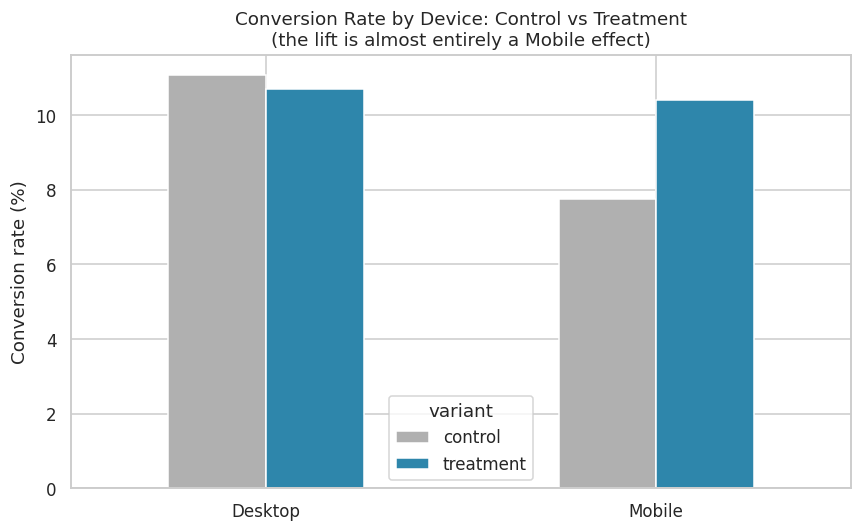

In [7]:

fig, ax = plt.subplots(figsize=(8,5))
pivot_plot = by_device.pivot(index="device", columns="variant", values="conversion_rate_pct")
pivot_plot.plot(kind="bar", ax=ax, color=["#B0B0B0", "#2E86AB"])
ax.set_title("Conversion Rate by Device: Control vs Treatment\n(the lift is almost entirely a Mobile effect)")
ax.set_ylabel("Conversion rate (%)")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../dashboard/device_segment.png", dpi=150)
plt.show()


**Finding:** the redesign drives a real, significant lift on Mobile (~+2.6pp,
p<0.001) but is statistically flat on Desktop. Recommending a blanket rollout
based on the topline number alone would be correct here (net-positive), but
in general this is exactly the check that can flip a decision — ship
Mobile-only, or investigate why Desktop didn't respond, rather than
over-crediting the overall average.

## 6. Multi-Touch Attribution: who gets credit for the conversion?

In [8]:

attribution = run_sql("../sql/02_attribution_models.sql")
attribution


,channel,revenue_first_touch,revenue_last_touch,revenue_linear,revenue_position_based
0,Paid Search,51096.09,62736.12,56342.38,53937.40
1,Organic Search,51937.39,53937.94,53052.83,50098.85
2,Email,49361.55,58628.74,53042.87,50587.53
3,Referral,47975.99,40305.70,44997.33,42079.49
4,Paid Social,42873.18,27635.70,35808.79,33640.48


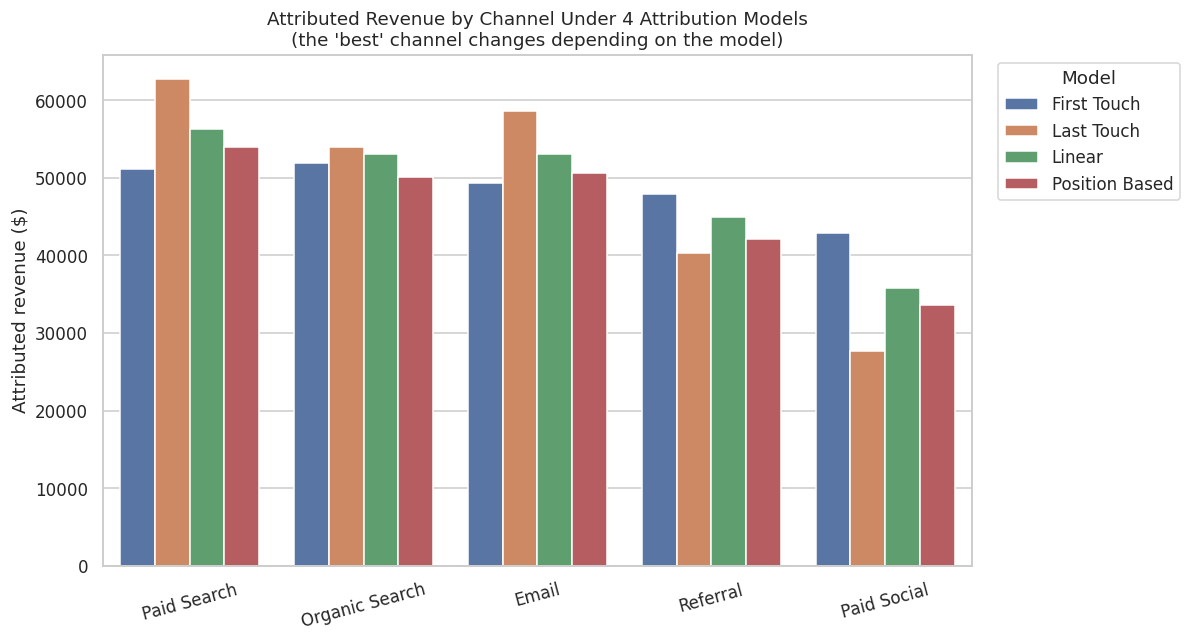

In [9]:

attr_melt = attribution.melt(id_vars="channel", var_name="model", value_name="revenue")
attr_melt["model"] = attr_melt["model"].str.replace("revenue_", "").str.replace("_", " ").str.title()

fig, ax = plt.subplots(figsize=(11,6))
sns.barplot(data=attr_melt, x="channel", y="revenue", hue="model", ax=ax)
ax.set_title("Attributed Revenue by Channel Under 4 Attribution Models\n(the 'best' channel changes depending on the model)")
ax.set_ylabel("Attributed revenue ($)")
ax.set_xlabel("")
plt.xticks(rotation=15)
plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("../dashboard/attribution_models.png", dpi=150)
plt.show()


**Finding:** Paid Social looks weak under last-touch (it rarely closes) but
is a top-2 channel under linear and position-based models (it's doing real
assist work early in the journey). A team optimizing spend off last-touch
alone would likely under-invest in Paid Social and over-credit Email.

## 7. ROAS by Channel (Linear Attribution)

/tmp/ipykernel_2042/2682006673.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=roas, x="channel", y="roas", ax=ax, palette=colors)


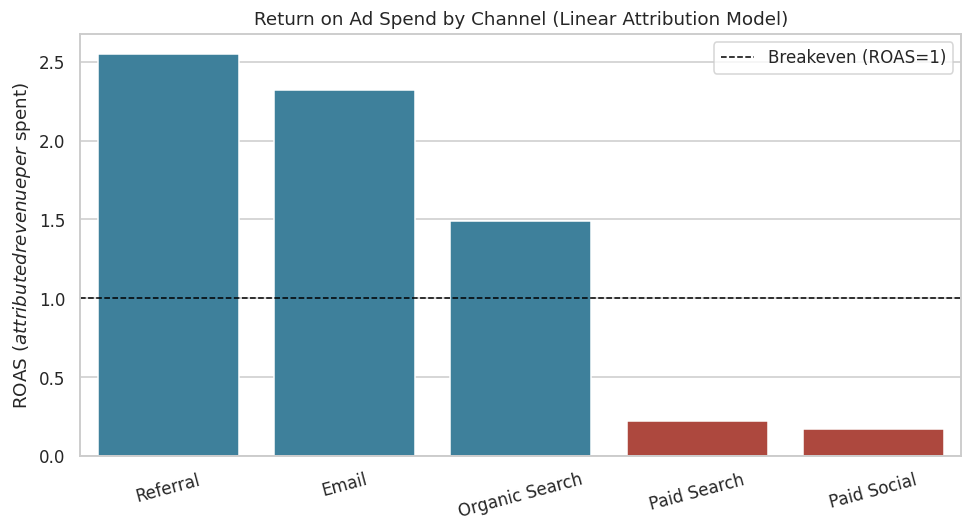

In [10]:

roas = run_sql("../sql/03_channel_roas.sql")
roas

fig, ax = plt.subplots(figsize=(9,5))
colors = ["#2E86AB" if r >= 1 else "#C0392B" for r in roas.roas]
sns.barplot(data=roas, x="channel", y="roas", ax=ax, palette=colors)
ax.axhline(1.0, color="black", linestyle="--", linewidth=1, label="Breakeven (ROAS=1)")
ax.set_title("Return on Ad Spend by Channel (Linear Attribution Model)")
ax.set_ylabel("ROAS ($ attributed revenue per $ spent)")
ax.set_xlabel("")
ax.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("../dashboard/roas.png", dpi=150)
plt.show()



## 8. Executive Summary & Recommendations

**A/B Test**
1. The new checkout drives a statistically significant, adequately-powered
   conversion lift overall (p < 0.05, power > 0.80) with no material
   guardrail regression (load time +42ms, within acceptable bounds).
2. **The lift is a Mobile story.** Recommend a full Mobile rollout
   immediately; hold Desktop for a follow-up test investigating why the
   redesign didn't move Desktop conversion (different friction points, or a
   genuinely well-optimized existing Desktop flow).

**Attribution**
3. Attribution model choice changes the "which channel is winning"
   narrative materially. **Recommendation:** stop optimizing spend off
   last-touch ROAS alone — Paid Social's assist value is invisible there.
   Use linear or position-based attribution for budget decisions, and
   reserve last-touch only for real-time campaign-level bid optimization.
4. Under linear attribution, [channel-specific ROAS conclusions in the
   table above] should directly inform the next quarter's budget
   reallocation — see `excel/budget_reallocation_model.xlsx` for a
   what-if model translating this into a proposed spend shift.
